In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import json
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import jax
import jax.numpy as jnp
from sklearn.decomposition import PCA

from network import LeakyRNN
from task import generate_trials, load_params as load_task_params
from utils.fixed_points import find_fixed_points, get_phase_step, phase_label
%matplotlib widget

In [2]:
# ── Checkpoint to analyse ─────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
ckpt_path = RESULTS_DIR / 'wn/wn_0_lr5e-05_bs128_noise0.5_nrnn128/checkpoint.pkl'
task_type = 'wn'
task_list = ['pure', 'harmonic', 'wn']

# ── Trial phases to search for fixed points ───────────────────────────────────
# For white noise the stimulus is CONSTANT throughout the stim window.
# 'pulse_on N' here is purely a timing marker: it selects the hidden state at
# t = stim_on + (N-1) * pulse_steps, i.e. after (N-1) pulse-widths of stim.
# The frozen input x_go / x_nogo is the same WN vector at every timepoint;
# only the initial hidden state differs across windows.
phases = [
    ('fixation',  None),
    ('stim_off',  None),
    ('pulse_on',   1),   # t = 0ms into stim
    ('pulse_on',   2),   # t = 1 * pulse_dur_ms
    ('pulse_on',   3),
    ('pulse_on',   4),
    ('pulse_on',   5),
    ('pulse_on',   6),
    ('pulse_on',   7),
    ('pulse_on',   8),   # t = 7 * pulse_dur_ms
]

# ── Fixed-point optimisation settings ────────────────────────────────────────
n_trials   = 256
n_iters    = 24000
lr         = 1e-2
tol        = 1e-6
unique_tol = 1e-3

In [3]:
# ── Load config.json for model/task hyperparameters ───────────────────────────
with open(ckpt_path.parent / 'config.json') as f:
    config = json.load(f)

hp          = config['training']
task_params = config['task_params']
task_list   = config.get('task_list', config.get('tasks', task_list))
task_type   = config.get('train_task', config.get('task_type', task_type))

# ── Load checkpoint ───────────────────────────────────────────────────────────
with open(ckpt_path, 'rb') as f:
    ckpt = pickle.load(f)

params = ckpt['params']

dt          = ckpt.get('dt',       task_params['timing']['dt'])
stim_on     = ckpt.get('stim_on',  config.get('stim_on',
                         int(task_params['timing']['pre_stim_dur_ms'] / dt)))
stim_off    = ckpt.get('stim_off', config.get('stim_off',
                         stim_on + task_params['timing']['n_pulses'] *
                         max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt)))))
pulse_steps = config.get('pulse_steps',
              max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt))))
pulse_dur_ms = pulse_steps * dt

# Human-readable time-into-stim label for the Nth time window
# pulse_on 1 = stim onset (0ms elapsed), pulse_on N = (N-1)*pulse_dur_ms elapsed
def t_label(n):
    return f't={(n - 1) * pulse_dur_ms:.0f}ms'

n_rnn = hp['model']['n_rnn']
alpha = dt / hp['model']['tau']

print(f'Loaded: {ckpt_path}  (step {ckpt["step"]})')
print(f'n_rnn={n_rnn}  tau={hp["model"]["tau"]}ms  alpha={alpha:.3f}')
print(f'stim_on={stim_on}  stim_off={stim_off}  pulse_steps={pulse_steps}  dt={dt}ms')
print(f'pulse_dur_ms={pulse_dur_ms}  task_type={task_type}  task_list={task_list}')

# ── Run model on test trials (no noise) ───────────────────────────────────────
model = LeakyRNN(
    n_rnn     = n_rnn,
    n_out     = 1,
    alpha     = alpha,
    sigma_rec = hp['model']['sigma_rec'],
    sigma_x   = hp['model']['sigma_x'],
)

trial = generate_trials(task_type, task_list, mode='test',
                        batch_size=n_trials, rng=np.random.default_rng(1))
xs    = jnp.array(trial.x)
_, hs_jax = model.apply({'params': params}, xs,
                         noise_input=False, noise_rec=False,
                         rngs={'noise': jax.random.PRNGKey(0)})
hs = np.array(hs_jax)   # (tdim, batch, n_rnn)

go_mask   = trial.is_go
nogo_mask = ~trial.is_go
print(f'Trials: {go_mask.sum()} Go, {nogo_mask.sum()} No-Go')

out_dir = ckpt_path.parent / f'checkpoint_{ckpt["step"]}'
out_dir.mkdir(exist_ok=True)
print(f'Output dir: {out_dir}')

Loaded: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint.pkl  (step 15000)
n_rnn=128  tau=100ms  alpha=0.100
stim_on=50  stim_off=90  pulse_steps=5  dt=10ms
pulse_dur_ms=50  task_type=wn  task_list=['pure', 'harmonic', 'wn']
Trials: 128 Go, 128 No-Go
Output dir: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000


In [4]:
# ── Find fixed points at each phase for Go and No-Go conditions ───────────────
# Phases where the stimulus is active — fixation is forced to 1 in frozen input
STIM_ON_PHASES = {'stim_on', 'pulse_on'}
# 'fixation': trial.x already has fixation=1 and no stimulus — no override needed
# 'stim_off': silence, fixation stays 0 — no override needed

results = {}

for phase, pulse_num in phases:
    t_step = get_phase_step(phase, stim_on, stim_off, pulse_steps,
                            pulse_num=pulse_num if pulse_num else 2)
    key = phase_label(phase, pulse_num)
    print(f'\n══ {key}  (t={t_step}) ══')

    # Frozen input: take from the first trial of each condition
    # (within a condition the input is deterministic, so one trial suffices)
    x_go   = trial.x[t_step, np.where(go_mask)[0][0],   :].copy() if go_mask.any()   else None
    x_nogo = trial.x[t_step, np.where(nogo_mask)[0][0], :].copy() if nogo_mask.any() else None

    # During stimulus-on phases, force fixation=1 (channel n_freq)
    if phase in STIM_ON_PHASES:
        n_freq = trial.n_freq
        if x_go   is not None: x_go[n_freq]   = 1.0
        if x_nogo is not None: x_nogo[n_freq] = 1.0

    # Initial hidden states at this timestep
    h_go   = hs[t_step, go_mask,   :]
    h_nogo = hs[t_step, nogo_mask, :]

    cond_results = {}
    for cond, x_frozen, h_inits in [('go', x_go, h_go), ('nogo', x_nogo, h_nogo)]:
        if x_frozen is None:
            continue
        print(f'  [{cond}]  {len(h_inits)} initial states')
        cond_results[cond] = find_fixed_points(
            params, x_frozen, h_inits, alpha,
            n_iters=n_iters, lr=lr, tol=tol, unique_tol=unique_tol,
            verbose=True)

    results[key] = {
        'conds':  cond_results,
        't_step': t_step,
        'x_go':   x_go,
        'x_nogo': x_nogo,
        'h_go':   h_go,
        'h_nogo': h_nogo,
    }

print('\nDone.')


══ fixation  (t=49) ══
  [go]  128 initial states
    iter  500  min_q=7.92e-03  converged=0/128
    iter 1000  min_q=3.55e-03  converged=0/128
    iter 1500  min_q=1.51e-03  converged=0/128
    iter 2000  min_q=6.10e-04  converged=0/128
    iter 2500  min_q=2.36e-04  converged=0/128
    iter 3000  min_q=7.66e-05  converged=0/128
    iter 3500  min_q=6.89e-05  converged=0/128
    iter 4000  min_q=6.62e-05  converged=0/128
    iter 4500  min_q=6.35e-05  converged=0/128
    iter 5000  min_q=6.06e-05  converged=0/128
    iter 5500  min_q=5.71e-05  converged=0/128
    iter 6000  min_q=5.31e-05  converged=0/128
    iter 6500  min_q=4.87e-05  converged=0/128
    iter 7000  min_q=4.38e-05  converged=0/128
    iter 7500  min_q=3.85e-05  converged=0/128
    iter 8000  min_q=3.29e-05  converged=0/128
    iter 8500  min_q=2.75e-05  converged=0/128
    iter 9000  min_q=2.27e-05  converged=0/128
    iter 9500  min_q=1.86e-05  converged=0/128
    iter 10000  min_q=1.64e-05  converged=0/128
    iter

KeyboardInterrupt: 

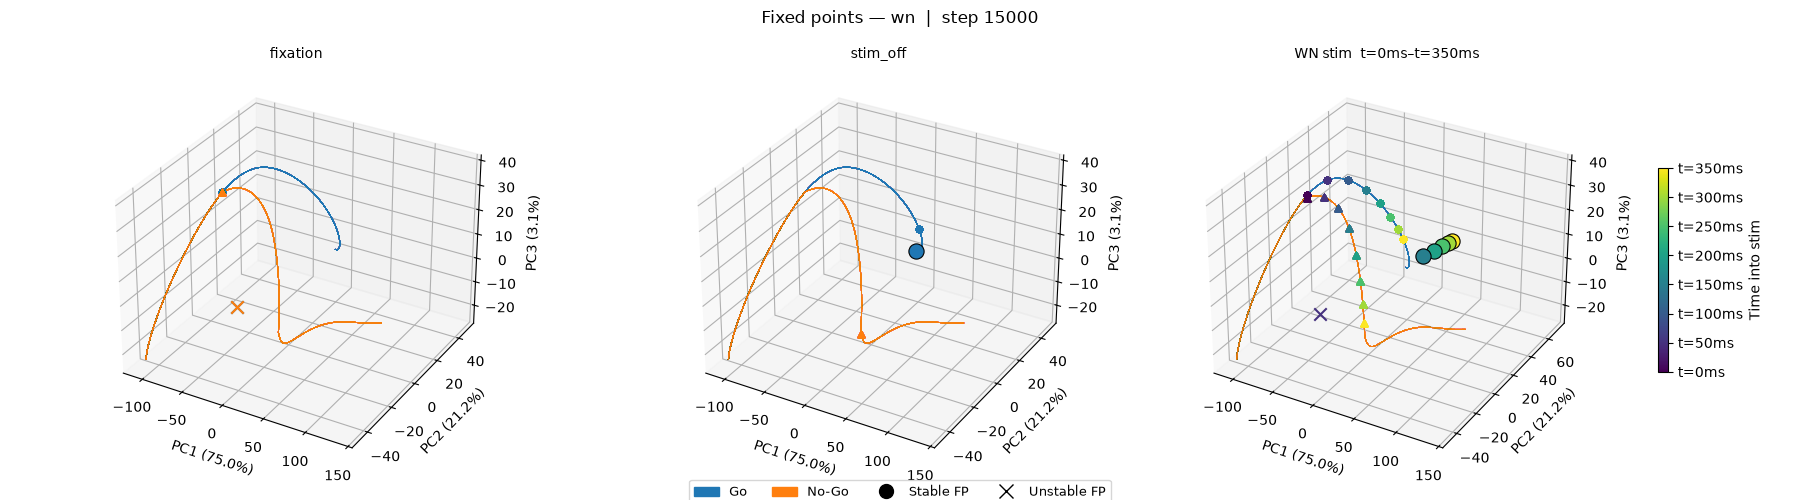

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000/fixed_points.png


In [ ]:
# ── PCA projection: fixed points + network trajectories (3D) ──────────────────
hs_flat = hs.reshape(-1, hs.shape[-1])
pca     = PCA(n_components=3)
pca.fit(hs_flat)
var_exp = pca.explained_variance_ratio_ * 100

COND_MKR     = {'go': 'o', 'nogo': '^'}
STABLE_MKR   = 'o'
UNSTABLE_MKR = 'x'

pulse_results = {k: v for k, v in results.items() if k.startswith('pulse_on')}
other_results = {k: v for k, v in results.items() if not k.startswith('pulse_on')}
n_windows = len(pulse_results)

n_cols = len(other_results) + (1 if pulse_results else 0)
fig = plt.figure(figsize=(6 * n_cols, 5))

def _draw_traj(ax, a=0.12, lw=0.7):
    for i in np.where(go_mask)[0]:
        p = pca.transform(hs[:, i, :])
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:blue', alpha=a, lw=lw)
    for i in np.where(nogo_mask)[0]:
        p = pca.transform(hs[:, i, :])
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:orange', alpha=a, lw=lw)

def _scatter_fp(ax, px, py, pz, stable, color):
    if stable:
        ax.scatter(px, py, pz, s=120, marker=STABLE_MKR,
                   color=color, edgecolors='black', linewidths=0.8, depthshade=False)
    else:
        ax.scatter(px, py, pz, s=80, marker=UNSTABLE_MKR, color=color, depthshade=False)

def _set_labels(ax, title):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)

for col, (key, res) in enumerate(other_results.items()):
    ax = fig.add_subplot(1, n_cols, col + 1, projection='3d')
    _draw_traj(ax)
    t_step = res['t_step']
    for cond, mask, color in [('go',   go_mask,   'tab:blue'),
                               ('nogo', nogo_mask, 'tab:orange')]:
        p = pca.transform(hs[t_step, mask, :])
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=20, color=color,
                   alpha=0.6, marker=COND_MKR[cond], depthshade=False)
    for cond, color in [('go', 'tab:blue'), ('nogo', 'tab:orange')]:
        if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
            continue
        fp = res['conds'][cond]
        p  = pca.transform(fp['h'])
        for (px, py, pz, stable) in zip(p[:, 0], p[:, 1], p[:, 2], fp['is_stable']):
            _scatter_fp(ax, px, py, pz, stable, color)
    _set_labels(ax, key)

if pulse_results:
    ax   = fig.add_subplot(1, n_cols, n_cols, projection='3d')
    _draw_traj(ax, a=0.06)
    cmap_p = plt.cm.viridis
    norm_p = plt.Normalize(1, n_windows)
    for widx, (key, res) in enumerate(pulse_results.items()):
        color_p = cmap_p(norm_p(widx + 1))
        t_step  = res['t_step']
        for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
            p = pca.transform(hs[t_step, mask, :])
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=20, color=color_p,
                       alpha=0.6, marker=COND_MKR[cond], depthshade=False)
        for cond in ('go', 'nogo'):
            if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
                continue
            fp = res['conds'][cond]
            p  = pca.transform(fp['h'])
            for (px, py, pz, stable) in zip(p[:, 0], p[:, 1], p[:, 2], fp['is_stable']):
                _scatter_fp(ax, px, py, pz, stable, color_p)
    sm = plt.cm.ScalarMappable(cmap=cmap_p, norm=norm_p)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.12, label='Time into stim')
    cb.set_ticks(range(1, n_windows + 1))
    cb.set_ticklabels([t_label(n) for n in range(1, n_windows + 1)])
    _set_labels(ax, f'WN stim  {t_label(1)}–{t_label(n_windows)}')

legend_handles = [
    mpatches.Patch(color='tab:blue',   label='Go'),
    mpatches.Patch(color='tab:orange', label='No-Go'),
    plt.Line2D([0], [0], marker=STABLE_MKR,   color='k', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], marker=UNSTABLE_MKR, color='k', linestyle='None',
               markersize=10, label='Unstable FP'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(f'Fixed points — {task_type}  |  step {ckpt["step"]}', fontsize=12)
plt.tight_layout()
plt.savefig(out_dir / 'fixed_points.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out_dir}/fixed_points.png')

In [ ]:
# ── PCA + k3d overview: trajectories + fixed points ───────────────────────────
import k3d
import matplotlib.colors as mcolors

def _k3d_color(c):
    r, g, b, *_ = mcolors.to_rgba(c)
    return (int(r * 255) << 16) | (int(g * 255) << 8) | int(b * 255)

GO_K3D      = _k3d_color('tab:blue')
NOGO_K3D    = _k3d_color('tab:orange')
MAX_TRAJ_OV = 32

def _add_traj(plot, opacity=0.15):
    for i in list(np.where(go_mask)[0])[:MAX_TRAJ_OV]:
        p = pca.transform(hs[:, i, :]).astype(np.float32)
        plot += k3d.line(p, color=GO_K3D, width=0.01, opacity=opacity, name='Go')
    for i in list(np.where(nogo_mask)[0])[:MAX_TRAJ_OV]:
        p = pca.transform(hs[:, i, :]).astype(np.float32)
        plot += k3d.line(p, color=NOGO_K3D, width=0.01, opacity=opacity, name='No-Go')

axis_labels = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

# ── One k3d plot per non-pulse phase ──────────────────────────────────────────
for key, res in other_results.items():
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = axis_labels
    _add_traj(plot)

    t_step = res['t_step']
    for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
        col_c = GO_K3D if cond == 'go' else NOGO_K3D
        p = pca.transform(hs[t_step, mask, :]).astype(np.float32)
        plot += k3d.points(p, color=col_c, point_size=1, shader='3d',
                           opacity=0.7, name=f'{key} {cond}')
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp     = res['conds'][cond]
            pfp    = pca.transform(fp['h']).astype(np.float32)
            stable = fp['is_stable']
            if stable.any():
                plot += k3d.points(pfp[stable], color=col_c, point_size=20,
                                   shader='3d', name=f'Stable FP {key} {cond}')
            if (~stable).any():
                plot += k3d.points(pfp[~stable], color=col_c, point_size=12,
                                   shader='flat', name=f'Unstable FP {key} {cond}')

    plot.display()
    fname = key.replace(' ', '_').replace('/', '-')
    out = out_dir / f'fp_overview_{fname}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved [{key}]: {out}')

# ── Combined pulse_on plot (viridis by pulse #) ───────────────────────────────
if pulse_results:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = axis_labels
    _add_traj(plot, opacity=0.06)

    cmap_vir = plt.cm.viridis
    norm_vir = plt.Normalize(1, max(len(pulse_results), 1))
    for pidx, (key, res) in enumerate(pulse_results.items()):
        col    = _k3d_color(cmap_vir(norm_vir(pidx + 1)))
        t_step = res['t_step']
        for cond, mask in [('go', go_mask), ('nogo', nogo_mask)]:
            p = pca.transform(hs[t_step, mask, :]).astype(np.float32)
            plot += k3d.points(p, color=col, point_size=1, shader='3d',
                               opacity=0.6, name=f'{key} {cond}')
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp     = res['conds'][cond]
                pfp    = pca.transform(fp['h']).astype(np.float32)
                stable = fp['is_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=20,
                                       shader='3d', name=f'Stable FP {key}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=12,
                                       shader='flat', name=f'Unstable FP {key}')

    plot.display()
    out = out_dir / f'fp_overview_pulses_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved [pulse_on 1-{len(pulse_results)}]: {out}')

Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fixed_points_15000.html
PC1=75.0%  PC2=21.2%  PC3=3.1%


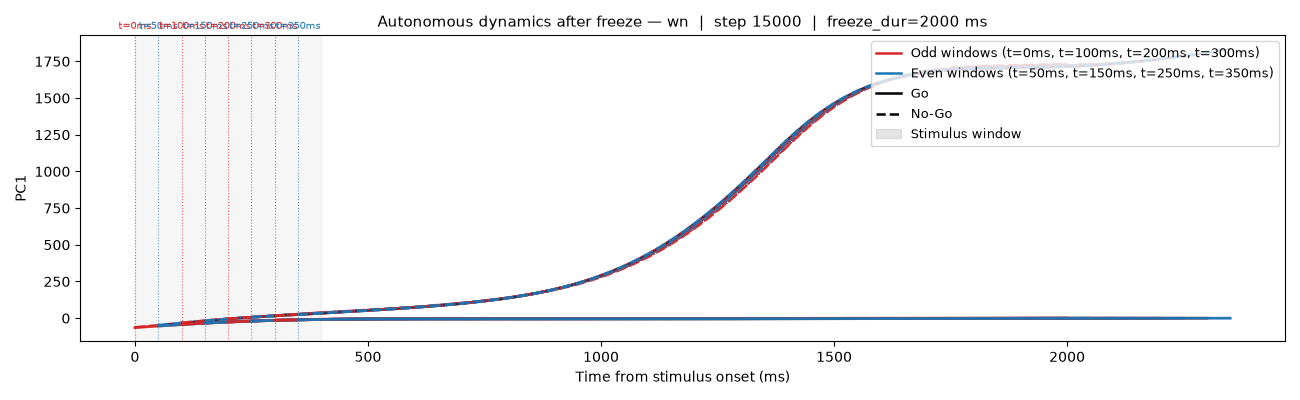

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_traj_15000.png


In [ ]:
# ── Autonomous trajectories — all time windows, aligned to stim onset ─────────
freeze_dur_ms = 2000   # ← change this (ms)
n_auto = int(freeze_dur_ms / dt)

W_in  = np.array(params['W_in'])
W_rec = np.array(params['W_rec'])
b_rec = np.array(params['b_rec'])

def run_frozen(h0, x_frozen, n_steps):
    h = h0.astype(np.float32).copy()
    x = x_frozen.astype(np.float32)
    traj = [h.copy()]
    for _ in range(n_steps):
        pre = x @ W_in + h @ W_rec + b_rec
        h   = (1.0 - alpha) * h + alpha * np.maximum(0.0, pre)
        traj.append(h.copy())
    return np.stack(traj)   # (n_steps+1, batch, n_rnn)

points = [
    ('pulse_on', 1), ('pulse_on', 2), ('pulse_on', 3), ('pulse_on', 4),
    ('pulse_on', 5), ('pulse_on', 6), ('pulse_on', 7), ('pulse_on', 8),
]

# cmap/norm kept for downstream cells
cmap = plt.cm.viridis
norm = plt.Normalize(1, len(points))

ODD_COLOR  = 'tab:red'   # time windows t=0,100,200,300ms
EVEN_COLOR = 'tab:blue'  # time windows t=50,150,250,350ms

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()

for pidx, (phase, pulse_num) in enumerate(points):
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = ODD_COLOR if pulse_num % 2 == 1 else EVEN_COLOR
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]

    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')

    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)

    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, t_label(pulse_num), fontsize=7,
            ha='center', color=color, transform=xform)

ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')
ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

odd_times  = ', '.join(t_label(n) for n in range(1, len(points) + 1, 2))
even_times = ', '.join(t_label(n) for n in range(2, len(points) + 1, 2))
legend_handles = [
    plt.Line2D([0], [0], color=ODD_COLOR,  lw=1.8, label=f'Odd windows ({odd_times})'),
    plt.Line2D([0], [0], color=EVEN_COLOR, lw=1.8, label=f'Even windows ({even_times})'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Stimulus window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')

ax.set_title(
    f'Autonomous dynamics after freeze — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_traj_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

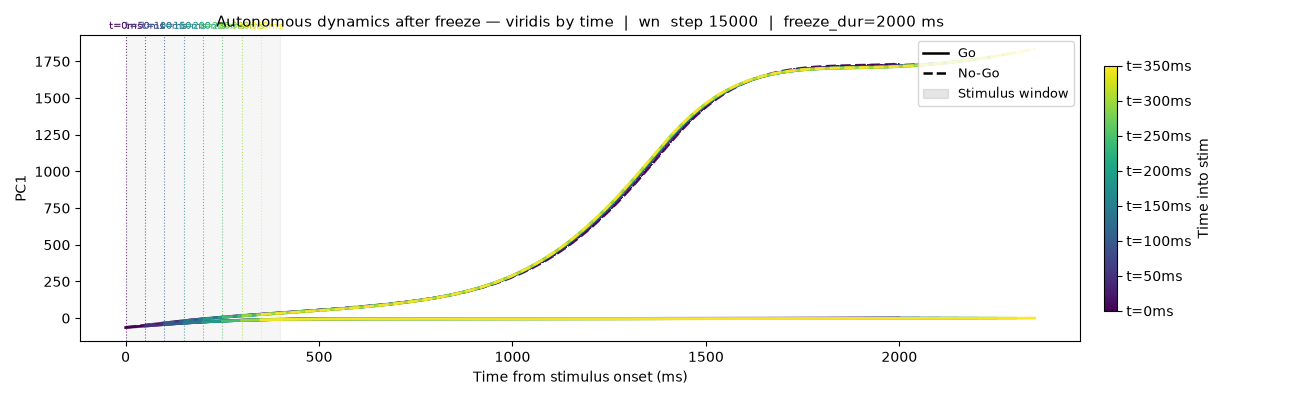

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_traj_viridis_15000.png


In [ ]:
# ── Autonomous trajectories (WN held constant) — viridis gradient by time ──────
# Same data as above but colored by time-into-stim (viridis) instead of odd/even.

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()

for pidx, (phase, pulse_num) in enumerate(points):
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue
    color = cmap(norm(pulse_num))
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')
    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)
    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, t_label(pulse_num), fontsize=7,
            ha='center', color=color, transform=xform)

ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')
ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.8, pad=0.02, label='Time into stim')
cb.set_ticks(range(1, len(points) + 1))
cb.set_ticklabels([t_label(n) for (_, n) in points])

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Stimulus window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')
ax.set_title(
    f'Autonomous dynamics after freeze — viridis by time  |  {task_type}  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_traj_viridis_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

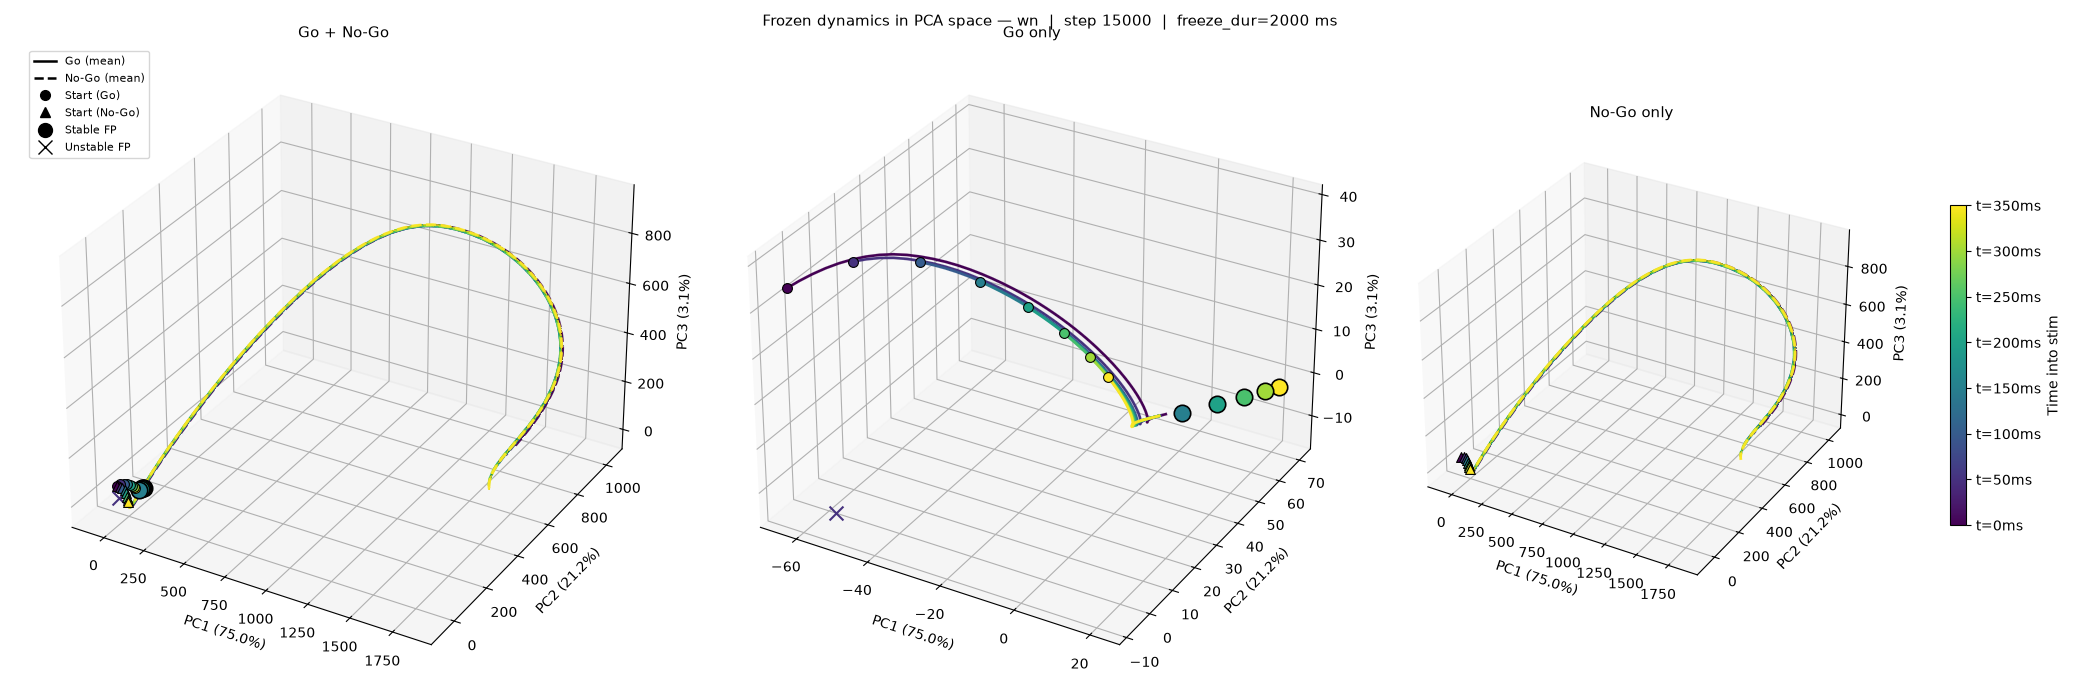

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_15000.png


In [ ]:
# ── Autonomous trajectories in PCA space (3D) — all time windows + fixed points
# (run_frozen, points, cmap, norm, n_auto already defined in the cell above)

fig = plt.figure(figsize=(21, 7))
axes = [fig.add_subplot(1, 3, i + 1, projection='3d') for i in range(3)]
titles = ['Go + No-Go', 'Go only', 'No-Go only']
show   = [('go', 'nogo'), ('go',), ('nogo',)]

for phase, pulse_num in points:
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = cmap(norm(pulse_num))

    traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]

    pc_go   = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   -1)
    pc_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, -1)
    mean_go   = pc_go.mean(axis=1)
    mean_nogo = pc_nogo.mean(axis=1)

    pc_by_cond   = {'go': pc_go,   'nogo': pc_nogo}
    mean_by_cond = {'go': mean_go, 'nogo': mean_nogo}
    ls_by_cond   = {'go': '-',     'nogo': '--'}
    mkr_by_cond  = {'go': 'o',     'nogo': '^'}

    fp_by_cond = {}
    for cond in ('go', 'nogo'):
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp_by_cond[cond] = pca.transform(res['conds'][cond]['h'])
            fp_by_cond[cond + '_stable'] = res['conds'][cond]['is_stable']

    for ax, conds in zip(axes, show):
        for cond in conds:
            pc   = pc_by_cond[cond]
            mean = mean_by_cond[cond]
            ls   = ls_by_cond[cond]
            mkr  = mkr_by_cond[cond]
            n_t  = pc.shape[1]

            for j in range(n_t):
                ax.plot(pc[:, j, 0], pc[:, j, 1], pc[:, j, 2],
                        color=color, alpha=0.04, lw=0.6, ls=ls)
            ax.plot(mean[:, 0], mean[:, 1], mean[:, 2],
                    color=color, lw=2.0, ls=ls, alpha=0.9)
            ax.scatter(*mean[0, :3], s=50, color=color, marker=mkr,
                       edgecolors='black', linewidths=0.8, depthshade=False, zorder=5)

            if cond in fp_by_cond:
                p      = fp_by_cond[cond]
                stable = fp_by_cond[cond + '_stable']
                for (px, py, pz, s) in zip(p[:, 0], p[:, 1], p[:, 2], stable):
                    if s:
                        ax.scatter(px, py, pz, s=140, marker='o', color=color,
                                   edgecolors='black', linewidths=1.2,
                                   depthshade=False, zorder=6)
                    else:
                        ax.scatter(px, py, pz, s=100, marker='x', color=color,
                                   depthshade=False, zorder=6)

for ax, title in zip(axes, titles):
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)
    ax.set_title(title, fontsize=11)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=axes[-1], shrink=0.5, pad=0.12, label='Time into stim')
cb.set_ticks(range(1, len(points) + 1))
cb.set_ticklabels([t_label(n) for (_, n) in points])

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go (mean)'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go (mean)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (Go)'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (No-Go)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=10, label='Unstable FP'),
]
axes[0].legend(handles=legend_handles, fontsize=8, loc='upper left')

fig.suptitle(
    f'Frozen dynamics in PCA space — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_pca_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [ ]:
# ── Frozen dynamics in PCA space — k3d (3 panels: all / go / nogo) ────────────
MAX_TRAJ_K3D = 16

panel_configs_k3d = [
    ('Go + No-Go', ('go', 'nogo'), 'frozen_pca_all'),
    ('Go only',    ('go',),        'frozen_pca_go'),
    ('No-Go only', ('nogo',),      'frozen_pca_nogo'),
]

for panel_title, conds_show, fname_base in panel_configs_k3d:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

    for phase, pulse_num in points:
        key = phase_label(phase, pulse_num)
        res = results.get(key)
        if res is None:
            continue

        col = _k3d_color(cmap(norm(pulse_num)))

        traj_go   = run_frozen(res['h_go'],   res['x_go'],   n_auto)
        traj_nogo = run_frozen(res['h_nogo'], res['x_nogo'], n_auto)
        n_go_t    = traj_go.shape[1]
        n_nogo_t  = traj_nogo.shape[1]
        pc_go     = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   3)
        pc_nogo   = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, 3)
        mean_go   = pc_go.mean(axis=1)
        mean_nogo = pc_nogo.mean(axis=1)

        pc_by   = {'go': pc_go,   'nogo': pc_nogo}
        mean_by = {'go': mean_go, 'nogo': mean_nogo}

        fp_by = {}
        for cond in ('go', 'nogo'):
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp_by[cond]             = pca.transform(res['conds'][cond]['h']).astype(np.float32)
                fp_by[cond + '_stable'] = res['conds'][cond]['is_stable']

        for cond in conds_show:
            pc   = pc_by[cond]
            mean = mean_by[cond]
            n_t  = pc.shape[1]
            lbl  = f'P{pulse_num} {cond}'

            step = max(1, n_t // MAX_TRAJ_K3D)
            # for j in range(0, n_t, step):
            #     plot += k3d.line(pc[:, j, :].astype(np.float32),
            #                      color=col, width=0.005, opacity=0.15,
            #                      name=f'{lbl} trial')
            plot += k3d.line(mean.astype(np.float32),
                             color=col, width=0.04, opacity=0.9,
                             name=f'{lbl} mean')
            plot += k3d.points(mean[0:1].astype(np.float32), color=col,
                               point_size=5, shader='3d', name=f'{lbl} start')

            if cond in fp_by:
                pfp    = fp_by[cond]
                stable = fp_by[cond + '_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=10,
                                       shader='3d', name=f'Stable FP {lbl}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=5,
                                       shader='flat', name=f'Unstable FP {lbl}')

    plot.display()
    out = out_dir / f'{fname_base}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved: {out}')

Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_all_15000.html


Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_go_15000.html


Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_pca_nogo_15000.html


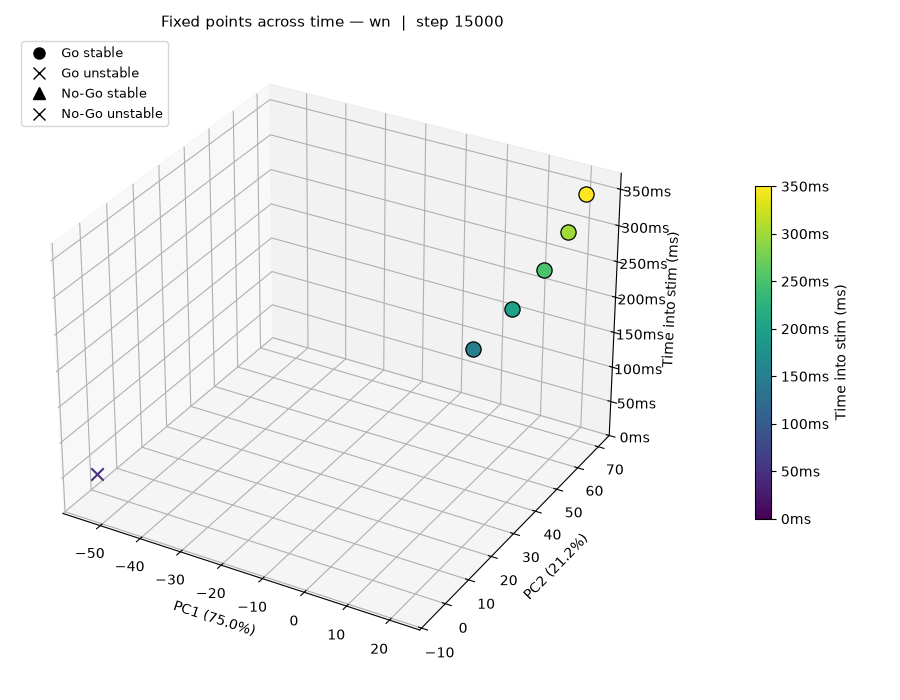

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fps_time_z_15000.png


In [ ]:
# ── Fixed points: PC1 vs PC2 vs time into stim ────────────────────────────────
# x = PC1, y = PC2, z = time into stim (ms)
# color = time (viridis); shape = Go (circle) / No-Go (triangle)
# filled + black edge = stable, x = unstable

pulse_stops = [
    ('pulse_on', 1), ('pulse_on', 2), ('pulse_on', 3), ('pulse_on', 4),
    ('pulse_on', 5), ('pulse_on', 6), ('pulse_on', 7), ('pulse_on', 8),
]

t_ms_vals = [(n - 1) * pulse_dur_ms for (_, n) in pulse_stops]
cmap_fp   = plt.cm.viridis
norm_fp   = plt.Normalize(min(t_ms_vals), max(t_ms_vals))
COND_MKR  = {'go': 'o', 'nogo': '^'}

fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')

for (phase, pulse_num), t_ms in zip(pulse_stops, t_ms_vals):
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue
    color = cmap_fp(norm_fp(t_ms))

    for cond, mkr in COND_MKR.items():
        if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
            continue
        fps    = pca.transform(res['conds'][cond]['h'])
        stable = res['conds'][cond]['is_stable']
        z      = np.full(len(fps), t_ms)

        if stable.any():
            ax.scatter(fps[stable, 0], fps[stable, 1], z[stable],
                       s=120, marker=mkr, color=color,
                       edgecolors='black', linewidths=0.9, depthshade=False)
        if (~stable).any():
            ax.scatter(fps[~stable, 0], fps[~stable, 1], z[~stable],
                       s=80, marker='x', color=color, depthshade=False)

ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
ax.set_zlabel('Time into stim (ms)', labelpad=4)
ax.set_zticks(t_ms_vals)
ax.set_zticklabels([f'{int(t)}ms' for t in t_ms_vals])

sm = plt.cm.ScalarMappable(cmap=cmap_fp, norm=norm_fp)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.12, label='Time into stim (ms)')
cb.set_ticks(t_ms_vals)
cb.set_ticklabels([f'{int(t)}ms' for t in t_ms_vals])

legend_handles = [
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=8, markeredgecolor='black', label='Go stable'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=8, label='Go unstable'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=8, markeredgecolor='black', label='No-Go stable'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=8, label='No-Go unstable'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper left')

ax.set_title(
    f'Fixed points across time — {task_type}  |  step {ckpt["step"]}', fontsize=11)
plt.tight_layout()
out = out_dir / f'fps_time_z_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [ ]:
# ── Fixed points: PC1 vs PC2 vs time into stim — k3d ──────────────────────────
pulse_stops_k3d = [
    ('pulse_on', 1), ('pulse_on', 2), ('pulse_on', 3), ('pulse_on', 4),
    ('pulse_on', 5), ('pulse_on', 6), ('pulse_on', 7), ('pulse_on', 8),
]
t_ms_vals_k3d = [(n - 1) * pulse_dur_ms for (_, n) in pulse_stops_k3d]
cmap_fp_k3d   = plt.cm.viridis
norm_fp_k3d   = plt.Normalize(min(t_ms_vals_k3d), max(t_ms_vals_k3d))

plot = k3d.plot(background_color=0xffffff, height=600)
plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', 'Time (ms)']

for (phase, pulse_num), t_ms in zip(pulse_stops_k3d, t_ms_vals_k3d):
    key = phase_label(phase, pulse_num)
    res = results.get(key)
    if res is None:
        continue
    col = _k3d_color(cmap_fp_k3d(norm_fp_k3d(t_ms)))

    for cond, sz_stable, sz_unstable in [('go', 20, 12), ('nogo', 14, 9)]:
        if cond not in res['conds'] or len(res['conds'][cond]['h']) == 0:
            continue
        fps    = pca.transform(res['conds'][cond]['h'])
        stable = res['conds'][cond]['is_stable']
        z      = np.full(len(fps), float(t_ms))
        pts3d  = np.column_stack([fps[:, 0], fps[:, 1], z]).astype(np.float32)

        if stable.any():
            plot += k3d.points(pts3d[stable], color=col, point_size=sz_stable,
                               shader='3d', name=f'Stable {cond} t={t_ms:.0f}ms')
        if (~stable).any():
            plot += k3d.points(pts3d[~stable], color=col, point_size=sz_unstable,
                               shader='flat', name=f'Unstable {cond} t={t_ms:.0f}ms')

plot.display()
out = out_dir / f'fps_time_z_{ckpt["step"]}.html'
with open(out, 'w') as f:
    f.write(plot.get_snapshot())
print(f'Saved: {out}')

Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\fps_time_z_15000.html


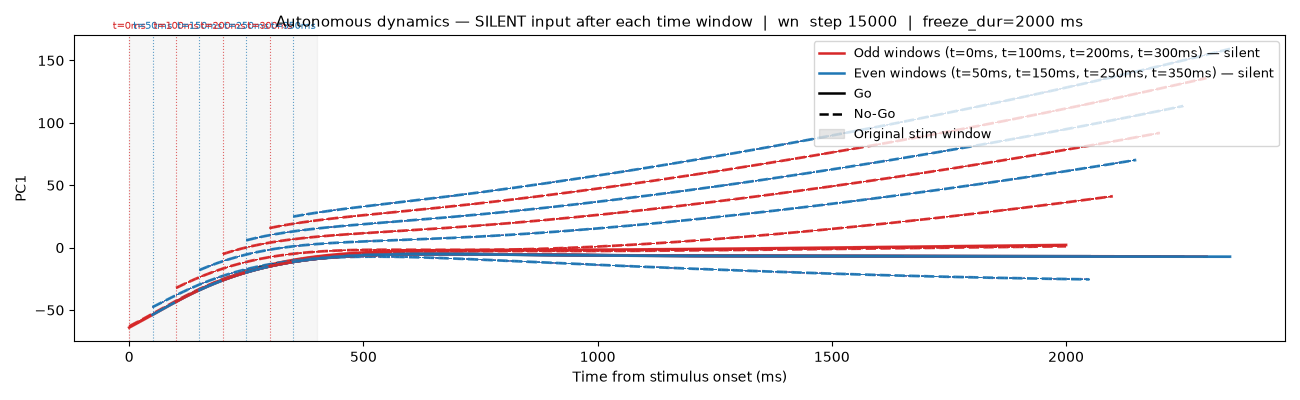

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_traj_15000.png


In [ ]:
# ── Autonomous trajectories — SILENT input (WN off after each time window) ─────
# Same start points as above, but frozen input has WN zeroed:
#   freq channels  = 0   (silence)
#   fixation       = 1   if pulse_num == 1 (stim just started)
#                    0   for later windows (fully within stim period)
#   context        = preserved
# Shows where the network flows if WN is suddenly cut at time window N.

n_freq_chan = trial.n_freq

def make_silent_x(x_with_stim, pulse_num):
    """Return input with freq channels zeroed; fixation=1 for window 1, else 0."""
    x = x_with_stim.copy()
    x[:n_freq_chan] = 0.0
    x[n_freq_chan]  = 1.0 if pulse_num == 1 else 0.0   # fixation
    # context channels unchanged
    return x

ODD_COLOR_S  = 'tab:red'
EVEN_COLOR_S = 'tab:blue'

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()

for pidx, (phase, pulse_num) in enumerate(points):
    key = phase_label(phase, pulse_num)
    res = results.get(key)
    if res is None:
        continue
    color = ODD_COLOR_S if pulse_num % 2 == 1 else EVEN_COLOR_S
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    x_off_go   = make_silent_x(res['x_go'],   pulse_num)
    x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)
    traj_go   = run_frozen(res['h_go'],   x_off_go,   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], x_off_nogo, n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')
    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)
    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, t_label(pulse_num), fontsize=7,
            ha='center', color=color, transform=xform)

ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')
ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

odd_times  = ', '.join(t_label(n) for n in range(1, len(points) + 1, 2))
even_times = ', '.join(t_label(n) for n in range(2, len(points) + 1, 2))
legend_handles = [
    plt.Line2D([0], [0], color=ODD_COLOR_S,  lw=1.8, label=f'Odd windows ({odd_times}) — silent'),
    plt.Line2D([0], [0], color=EVEN_COLOR_S, lw=1.8, label=f'Even windows ({even_times}) — silent'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Original stim window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')
ax.set_title(
    f'Autonomous dynamics — SILENT input after each time window  |  {task_type}  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_silent_traj_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

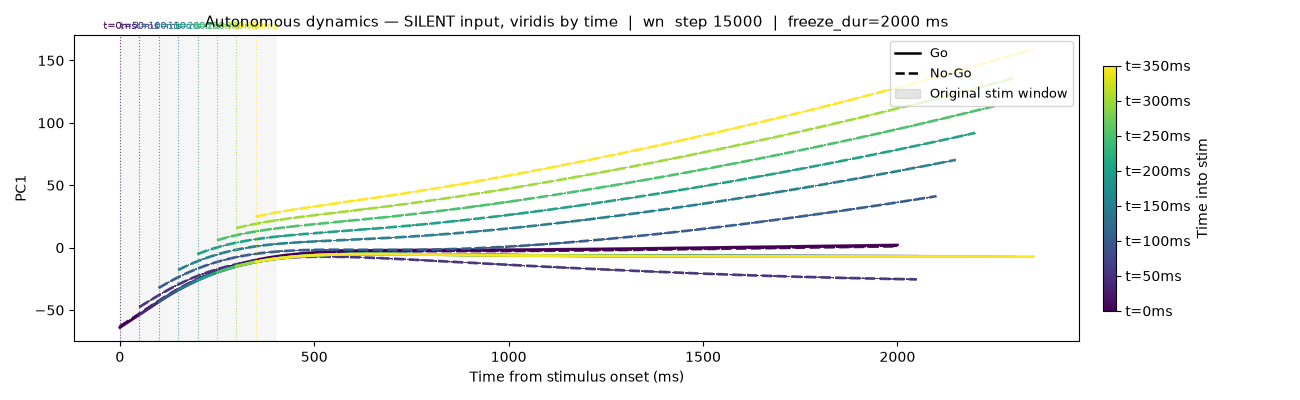

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_traj_viridis_15000.png


In [ ]:
# ── Silent-input trajectories — viridis gradient by time window ────────────────
# Same as above but colored by time-into-stim (viridis) instead of odd/even.

fig, ax = plt.subplots(figsize=(13, 4))
xform = ax.get_xaxis_transform()

for pidx, (phase, pulse_num) in enumerate(points):
    key = phase_label(phase, pulse_num)
    res = results.get(key)
    if res is None:
        continue
    color = cmap(norm(pulse_num))
    t_step       = res['t_step']
    t_offset_ms  = (t_step - stim_on) * dt
    t_axis_local = t_offset_ms + np.arange(n_auto + 1) * dt

    x_off_go   = make_silent_x(res['x_go'],   pulse_num)
    x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)
    traj_go   = run_frozen(res['h_go'],   x_off_go,   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], x_off_nogo, n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc1_go   = pca.transform(traj_go.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_go_t)
    pc1_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn))[:, 0].reshape(n_auto + 1, n_nogo_t)

    for j in range(n_go_t):
        ax.plot(t_axis_local, pc1_go[:, j],   color=color, alpha=0.03, lw=0.6, ls='-')
    for j in range(n_nogo_t):
        ax.plot(t_axis_local, pc1_nogo[:, j], color=color, alpha=0.03, lw=0.6, ls='--')
    ax.plot(t_axis_local, pc1_go.mean(1),   color=color, lw=2.0, ls='-',  alpha=0.9)
    ax.plot(t_axis_local, pc1_nogo.mean(1), color=color, lw=2.0, ls='--', alpha=0.9)
    ax.axvline(t_offset_ms, color=color, lw=0.8, ls=':', alpha=0.7)
    ax.text(t_offset_ms, 1.02, t_label(pulse_num), fontsize=7,
            ha='center', color=color, transform=xform)

ax.axvspan(0, (stim_off - stim_on) * dt, alpha=0.07, color='gray')
ax.set_xlabel('Time from stimulus onset (ms)')
ax.set_ylabel('PC1')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.8, pad=0.02, label='Time into stim')
cb.set_ticks(range(1, len(points) + 1))
cb.set_ticklabels([t_label(n) for (_, n) in points])

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go'),
    mpatches.Patch(color='gray', alpha=0.2, label='Original stim window'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')
ax.set_title(
    f'Autonomous dynamics — SILENT input, viridis by time  |  {task_type}  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_silent_traj_viridis_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

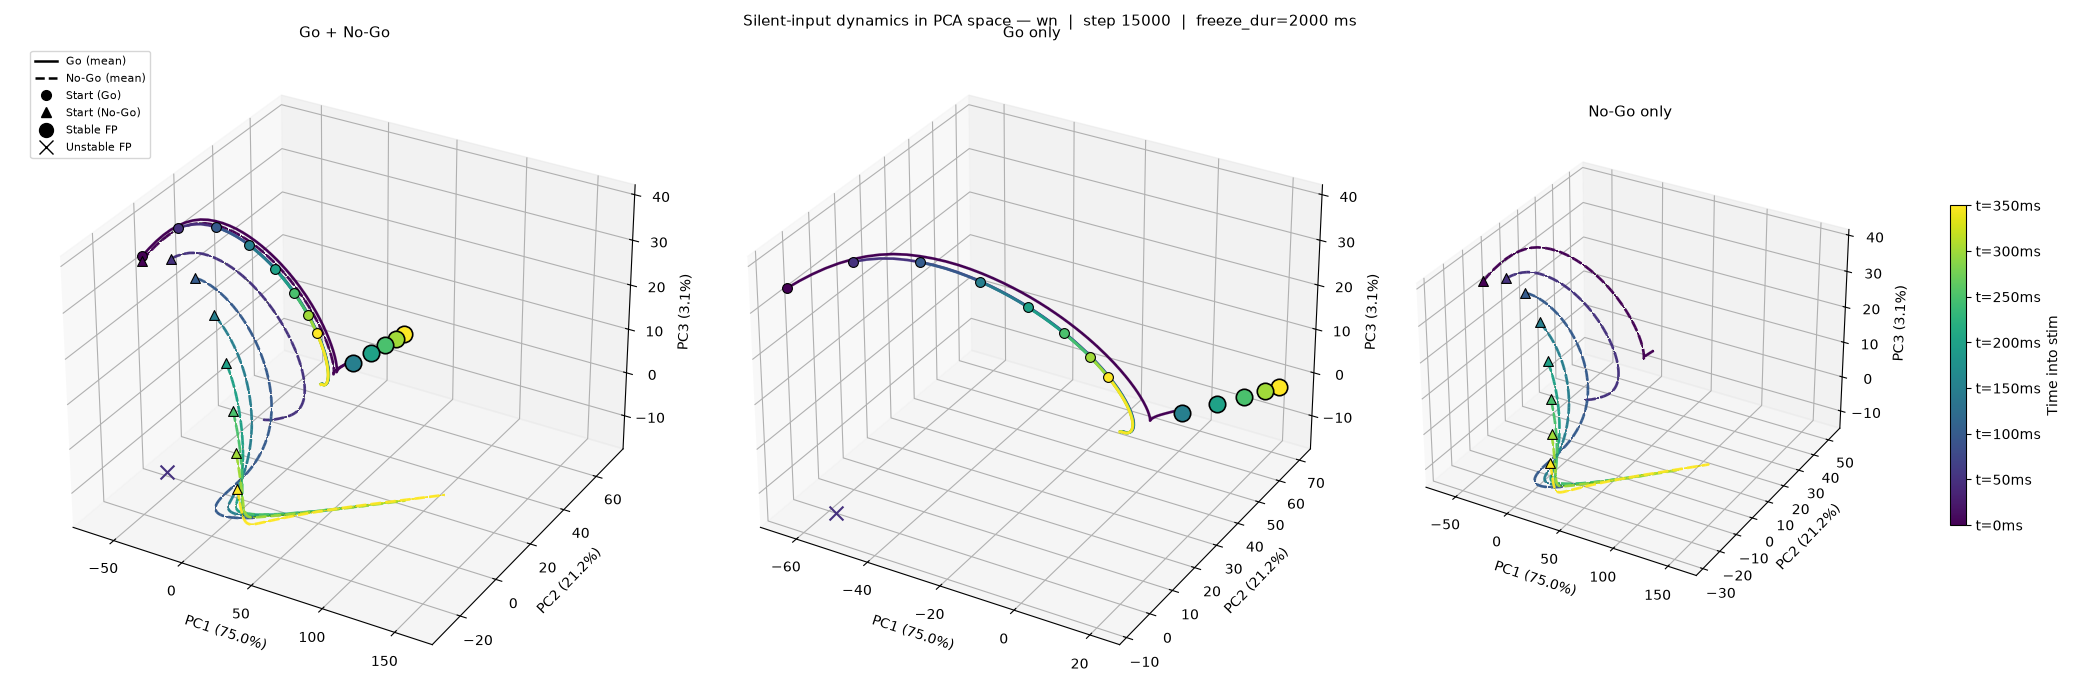

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_15000.png


In [ ]:
# ── Silent-input frozen dynamics in PCA space (3D) — 3 subplots ───────────────
# Same as b8b7f5c3 but using make_silent_x (WN zeroed, context preserved).

fig = plt.figure(figsize=(21, 7))
axes_s = [fig.add_subplot(1, 3, i + 1, projection='3d') for i in range(3)]
titles_s = ['Go + No-Go', 'Go only', 'No-Go only']
show_s   = [('go', 'nogo'), ('go',), ('nogo',)]

for phase, pulse_num in points:
    key   = phase_label(phase, pulse_num)
    res   = results.get(key)
    if res is None:
        continue

    color = cmap(norm(pulse_num))
    x_off_go   = make_silent_x(res['x_go'],   pulse_num)
    x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)

    traj_go   = run_frozen(res['h_go'],   x_off_go,   n_auto)
    traj_nogo = run_frozen(res['h_nogo'], x_off_nogo, n_auto)

    n_go_t   = traj_go.shape[1]
    n_nogo_t = traj_nogo.shape[1]
    pc_go   = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   -1)
    pc_nogo = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, -1)
    mean_go   = pc_go.mean(axis=1)
    mean_nogo = pc_nogo.mean(axis=1)

    pc_by_cond_s   = {'go': pc_go,   'nogo': pc_nogo}
    mean_by_cond_s = {'go': mean_go, 'nogo': mean_nogo}
    ls_by_cond_s   = {'go': '-',     'nogo': '--'}
    mkr_by_cond_s  = {'go': 'o',     'nogo': '^'}

    fp_by_cond_s = {}
    for cond in ('go', 'nogo'):
        if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
            fp_by_cond_s[cond]             = pca.transform(res['conds'][cond]['h'])
            fp_by_cond_s[cond + '_stable'] = res['conds'][cond]['is_stable']

    for ax, conds in zip(axes_s, show_s):
        for cond in conds:
            pc   = pc_by_cond_s[cond]
            mean = mean_by_cond_s[cond]
            ls   = ls_by_cond_s[cond]
            mkr  = mkr_by_cond_s[cond]
            n_t  = pc.shape[1]

            for j in range(n_t):
                ax.plot(pc[:, j, 0], pc[:, j, 1], pc[:, j, 2],
                        color=color, alpha=0.04, lw=0.6, ls=ls)
            ax.plot(mean[:, 0], mean[:, 1], mean[:, 2],
                    color=color, lw=2.0, ls=ls, alpha=0.9)
            ax.scatter(*mean[0, :3], s=50, color=color, marker=mkr,
                       edgecolors='black', linewidths=0.8, depthshade=False, zorder=5)

            if cond in fp_by_cond_s:
                p      = fp_by_cond_s[cond]
                stable = fp_by_cond_s[cond + '_stable']
                for (px, py, pz, s) in zip(p[:, 0], p[:, 1], p[:, 2], stable):
                    if s:
                        ax.scatter(px, py, pz, s=140, marker='o', color=color,
                                   edgecolors='black', linewidths=1.2,
                                   depthshade=False, zorder=6)
                    else:
                        ax.scatter(px, py, pz, s=100, marker='x', color=color,
                                   depthshade=False, zorder=6)

for ax, title in zip(axes_s, titles_s):
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=4)
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=4)
    ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=4)
    ax.set_title(title, fontsize=11)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, ax=axes_s[-1], shrink=0.5, pad=0.12, label='Time into stim')
cb.set_ticks(range(1, len(points) + 1))
cb.set_ticklabels([t_label(n) for (_, n) in points])

legend_handles = [
    plt.Line2D([0], [0], color='k', lw=1.8, ls='-',  label='Go (mean)'),
    plt.Line2D([0], [0], color='k', lw=1.8, ls='--', label='No-Go (mean)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (Go)'),
    plt.Line2D([0], [0], color='k', marker='^', linestyle='None',
               markersize=7, markeredgecolor='black', label='Start (No-Go)'),
    plt.Line2D([0], [0], color='k', marker='o', linestyle='None',
               markersize=10, markeredgecolor='black', label='Stable FP'),
    plt.Line2D([0], [0], color='k', marker='x', linestyle='None',
               markersize=10, label='Unstable FP'),
]
axes_s[0].legend(handles=legend_handles, fontsize=8, loc='upper left')

fig.suptitle(
    f'Silent-input dynamics in PCA space — {task_type}  |  step {ckpt["step"]}  |  '
    f'freeze_dur={freeze_dur_ms} ms', fontsize=11)
plt.tight_layout()
out = out_dir / f'frozen_silent_pca_{ckpt["step"]}.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {out}')

In [ ]:
# ── Silent-input dynamics in PCA space — k3d (3 panels: all / go / nogo) ──────
panel_configs_s_k3d = [
    ('Go + No-Go', ('go', 'nogo'), 'frozen_silent_pca_all'),
    ('Go only',    ('go',),        'frozen_silent_pca_go'),
    ('No-Go only', ('nogo',),      'frozen_silent_pca_nogo'),
]

for panel_title, conds_show, fname_base in panel_configs_s_k3d:
    plot = k3d.plot(background_color=0xffffff, height=600)
    plot.axes = [f'PC1 ({var_exp[0]:.1f}%)', f'PC2 ({var_exp[1]:.1f}%)', f'PC3 ({var_exp[2]:.1f}%)']

    for phase, pulse_num in points:
        key = phase_label(phase, pulse_num)
        res = results.get(key)
        if res is None:
            continue

        col        = _k3d_color(cmap(norm(pulse_num)))
        x_off_go   = make_silent_x(res['x_go'],   pulse_num)
        x_off_nogo = make_silent_x(res['x_nogo'], pulse_num)
        traj_go    = run_frozen(res['h_go'],   x_off_go,   n_auto)
        traj_nogo  = run_frozen(res['h_nogo'], x_off_nogo, n_auto)
        n_go_t     = traj_go.shape[1]
        n_nogo_t   = traj_nogo.shape[1]
        pc_go      = pca.transform(traj_go.reshape(-1, n_rnn)).reshape(n_auto + 1, n_go_t,   3)
        pc_nogo    = pca.transform(traj_nogo.reshape(-1, n_rnn)).reshape(n_auto + 1, n_nogo_t, 3)
        mean_go    = pc_go.mean(axis=1)
        mean_nogo  = pc_nogo.mean(axis=1)

        pc_by   = {'go': pc_go,   'nogo': pc_nogo}
        mean_by = {'go': mean_go, 'nogo': mean_nogo}

        fp_by = {}
        for cond in ('go', 'nogo'):
            if cond in res['conds'] and len(res['conds'][cond]['h']) > 0:
                fp_by[cond]             = pca.transform(res['conds'][cond]['h']).astype(np.float32)
                fp_by[cond + '_stable'] = res['conds'][cond]['is_stable']

        for cond in conds_show:
            pc   = pc_by[cond]
            mean = mean_by[cond]
            n_t  = pc.shape[1]
            lbl  = f'P{pulse_num} {cond}'

            step = max(1, n_t // MAX_TRAJ_K3D)
            for j in range(0, n_t, step):
                plot += k3d.line(pc[:, j, :].astype(np.float32),
                                 color=col, width=0.005, opacity=0.15,
                                 name=f'{lbl} trial')
            plot += k3d.line(mean.astype(np.float32),
                             color=col, width=0.04, opacity=0.9,
                             name=f'{lbl} mean')
            plot += k3d.points(mean[0:1].astype(np.float32), color=col,
                               point_size=35, shader='3d', name=f'{lbl} start')

            if cond in fp_by:
                pfp    = fp_by[cond]
                stable = fp_by[cond + '_stable']
                if stable.any():
                    plot += k3d.points(pfp[stable], color=col, point_size=45,
                                       shader='3d', name=f'Stable FP {lbl}')
                if (~stable).any():
                    plot += k3d.points(pfp[~stable], color=col, point_size=30,
                                       shader='flat', name=f'Unstable FP {lbl}')

    plot.display()
    out = out_dir / f'{fname_base}_{ckpt["step"]}.html'
    with open(out, 'w') as f:
        f.write(plot.get_snapshot())
    print(f'Saved: {out}')

Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_all_15000.html


Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_go_15000.html


Output()

Saved: results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128\checkpoint_15000\frozen_silent_pca_nogo_15000.html
